Этот ноутбук содержит результаты исследования и ограничения измерений. Опыты проводились на узлах Slurm; графики встроены в ноутбук. Рядом находятся упрощённые скрипты для локального запуска: [PyTorch](ptq.py), [ONNX](onnx_quantize.py), [TensorRT](tensorrt_build.py).


# Pythia-160M: исследование PTQ

Результаты получены на CPU- и GPU-узлах cHARISMa в задачах Slurm. Модель `EleutherAI/pythia-160m`, кэшированная ревизия `50f5173d932e8e61f858120bcb800b97af589f46`; WikiText-2 raw, калибровка на train, sensitivity и выбор на validation, финальная оценка выбранных вариантов на test. Исходные результаты экспортированы в локальный архив `ptq-cluster-results-4518938.tar.gz`; метрики — в [проекте Comet](https://www.comet.com/adran-dasadfan/nfgo-pythia-ptq).



## Методика и воспроизведение

Модель Pythia-160M загружается с float32-весами. Калибровка оценивает диапазоны активаций только на train, параметры и список исключений выбираются на validation, итоговое качество — на test. Для симметричного INT8 шаг определяется по максимуму модуля: `s = max(|min|, |max|) / 127`, значение округляется и ограничивается диапазоном `[-127, 127]`, затем восстанавливается как `s × q`. Для аффинного случая отдельно рассчитывается zero-point; веса линейных слоёв квантуются отдельно по выходным каналам. ONNX Q/DQ для TensorRT использует signed симметричные активации и веса; zero-point проверяется автоматически.

Качество — средний NLL следующих токенов, perplexity `exp(NLL)` и доля точных next-token предсказаний. Сравнение совпадения с FP32 измеряет устойчивость предсказаний, а не правильность по разметке. SQNR слоёв вычисляется по энергии FP32-выхода и энергии локальной ошибки Q/DQ; его рейтинг строится на validation при FP32-входах и не является прямым измерением влияния на итоговый loss. Вариант со случайно выбранными FP32-слоями контролирует влияние количества исключений.

Все прогоны делались на выделенных узлах Slurm; для сопоставимых измерений фиксировались устройство A100, batch size 1, длина контекста, прогрев, число оцененных блоков и backend. В графах длина контекста фиксирована и равна 64; PyTorch-серия использует 256. Задержка prefill измеряет вызов модели без токенизации; отдельный decode-тест использует KV-cache. Результаты, калибровочные диапазоны, JSON и журналы экспортированы локально. По просьбе пользователя веса, engine и файлы серии удалены из `lisa-audio` после экспорта результатов. Для чтения рядом с ноутбуком приведены упрощённые скрипты [PyTorch](ptq.py), [ONNX](onnx_quantize.py) и [TensorRT](tensorrt_build.py); опубликованные результаты получены отдельными экспериментальными скриптами.



## Validation: Q/DQ-эмуляция, 32 блока по 256 токенов

| Вариант | Калибровочных блоков | Perplexity | Next-token accuracy | Размер checkpoint, МБ |
|---|---:|---:|---:|---:|
| FP32 | — | 35,70 | 36,86% | 652,87* |
| INT8 symmetric | 8 | 61,08 | 30,05% | 279,22 |
| INT8 affine | 8 | 52,46 | 31,04% | 279,22 |
| INT8 symmetric | 32 | 62,61 | 29,44% | 279,22 |
| INT8 affine | 32 | 52,94 | 30,98% | 279,22 |
| INT8 symmetric, 8 чувствительных слоёв FP32 | 32 | 40,66 | 35,33% | 335,81 |
| INT8 symmetric, 8 случайных слоёв FP32 | 32 | 55,89 | 31,57% | 323,41 |

* FP32 размер включает дополнительные файлы токенизатора, остальные размеры — один файл checkpoint. Они приведены для ориентира, но требуют выравнивания состава файлов для итогового сравнения.

Активации квантуются по min/max калибровочных данных; веса линейных слоёв — симметрично per-channel. Исправление 14 ноября: в этих прежних запусках выходная голова **также была квантована**, поскольку код исключал `embed_out`, а текущая модель называет её `lm_head`. Предыдущее утверждение о FP32-голове было ошибочным; результаты выше относятся к версии с квантованной головой. Результаты повтора с FP32-головой приведены ниже. Измерения скорости Q/DQ-кода относятся к эмуляции с float matmul, а не к оптимизированному INT8-инференсу. Запуски на общей ноде частично пересекались; их тайминги не следует считать строгим benchmark.

Чувствительность — SQNR выходов каждого слоя, измеренный на validation при FP32-входах и локальном квантовании одного слоя. Это локальная метрика, а не причинная оценка изменения perplexity; её применимость проверена отдельно сравнением исключения худших и случайных восьми слоёв. Таблица слоёв доступна в проекте Comet.



## Test: выбранные на validation конфигурации

| Вариант | Perplexity | Next-token accuracy | Токенов |
|---|---:|---:|---:|
| FP32 | 52,23 | 31,16% | 8 160 |
| INT8 affine, 8 калибровочных блоков | 72,31 | 26,81% | 8 160 |
| INT8 symmetric, 8 чувствительных слоёв FP32 | 58,50 | 30,09% | 8 160 |

Это первые 32 неперекрывающихся блока test; доверительные интервалы ещё не посчитаны. Данные WikiText могут пересекаться с предобучением модели. Ниже отдельно приведена оценка на всей доступной последовательности полных блоков test.



## A100: validation, 32 блока по 256 токенов

| Вариант | Perplexity | Next-token accuracy | Prefill p50 | Пик allocated GPU |
|---|---:|---:|---:|---:|
| FP32 | 35,70 | 36,86% | 9,45 мс | 764 771 328 Б |
| INT8 Q/DQ symmetric, калибровка 32 блока | 63,34 | 29,62% | 13,47 мс | 812 311 040 Б |
| INT8 Q/DQ affine, калибровка 32 блока | 52,83 | 31,32% | 13,72 мс | 813 163 008 Б |

Перечисленные измерения GPU относятся к PyTorch-allocated памяти и не учитывают всю память процесса. INT8 здесь эмулируется операциями Q/DQ и float matmul, а не выполняется оптимизированным INT8-ядром; ухудшение скорости и рост allocated-памяти не следует обобщать на TensorRT.

Повтор после исправления исключения `lm_head` (A100, validation, 32 калибровочных блока и 32 оценочных блока по 256 токенов):

| Вариант с головой FP32 | Perplexity | Next-token accuracy | Сохранённый checkpoint, МБ |
|---|---:|---:|---:|
| FP32 baseline | 35,70 | 36,86% | 652,87* |
| Symmetric INT8 | 62,31 | 29,64% | 394,93 |
| Affine INT8 | 52,26 | 31,57% | 394,93 |
| Symmetric INT8, 8 чувствительных слоёв FP32 | 39,95 | 35,51% | 451,52 |
| Symmetric INT8, 8 случайных слоёв FP32 | 55,12 | 31,63% | 439,12 |

Размеры FP32 и INT8 имеют разный состав файлов, см. примечание выше. Этот повтор заменяет ранее ошибочное описание FP32-головы, но не удаляет результаты прежнего варианта с квантованной головой.



## ONNX Runtime: фиксированная форма 1×64

Экспорт FP32 проверен против PyTorch (`allclose` с `rtol=atol=0.001`): max absolute error 0,00659, mean absolute error 0,000481. В экспорте используется фиксированная causal mask; её выход до экспорта проверен против стандартной маски PyTorch.

На 32 validation-блоках по 64 токена, 16 калибровочных блоков train: ONNX FP32 perplexity 71,42; Q/DQ для всех MatMul/Gemm — 1 131 444,66; только операции с постоянными весами — 745 401,26; дополнительно оставленная в FP32 голова — 1 395,97; дополнительно оставленные в FP32 восемь чувствительных слоёв — 719,48. Последний INT8-граф сохраняет плохое качество и пока не подходит для итогового сравнения развёртывания. Пиковый RSS процесса сравнения без квантования головы, включающего обе ONNX-сессии, составил 5 562 532 KiB; это не раздельная память моделей.

Дополнительный перебор для последней схемы, исключающей голову и восемь чувствительных слоёв:

| Калибровочных блоков | Веса | Perplexity |
|---:|---|---:|
| 32 | per-channel | 730,94 |
| 32 | per-tensor | 805,36 |
| 128 | per-channel | 726,77 |
| 128 | per-tensor | 860,38 |

Первый запуск per-tensor с 32 блоками завершился ошибкой из-за общего временного файла ONNX Runtime; успешные повторы используют отдельную копию графа. Показатели подтверждают, что один лишь перебор этих параметров не восстанавливает качество.

Для симметричного signed INT8 и 32 калибровочных блоков дополнительно исключены первые 16, 24, 32 и 40 позиций из рейтинга чувствительности. Perplexity составила 668,47; 596,08; 591,26; 464,55 при FP32 71,42. У последнего графа остаются восемь квантованных MatMul, преимущественно attention QKV. Для локализации ошибки выполнены отдельные проверки каждой из этих восьми операций; выборка и калибровка не пересекаются.

Изолированное квантование только одной из этих операций дало perplexity: QKV блоков 3, 4, 5, 6, 7, 10 и 11 — соответственно 78,61; 118,66; 110,68; 83,96; 87,99; 74,49 и 91,36; выходное attention-преобразование блока 11 — 71,43. Baseline — 71,42. Последний вариант квантует лишь одну операцию и почти не сжимает модель; он полезен для диагностики, но не является эквивалентом полного INT8.

ONNX Runtime CPU, полный test из 284 193 предсказываемых токенов, длина контекста 64 и восемь CPU-потоков:

| Граф | Perplexity | Next-token accuracy | p50, мс | Размер ONNX, МБ | Пиковый RSS, MiB |
|---|---:|---:|---:|---:|---:|
| FP32 | 90,067 | 26,805% | 44,79 | 649,57 | 1 843,68 |
| Одна INT8-операция | 90,050 | 26,810% | 45,71 | 647,91 | 1 838,83 |
| Две INT8-операции | 94,737 | 26,268% | 43,52 | 642,62 | 1 826,16 |

Первые два CPU-запуска выполнялись одновременно на одном узле, третий — позже; поэтому эти задержки не являются контролируемым сравнением ускорения. RSS включает сессию, данные и остальной процесс, а не только веса.

Выборочные signed INT8 Q/DQ-графы проверены в TensorRT на A100 на 4 511 полных блоках test, контекст 64:

| Вариант | Perplexity | Next-token accuracy | Prefill p50, мс | Размер engine, МБ |
|---|---:|---:|---:|---:|
| TensorRT FP32 | 90,095 | 26,810% | 1,298 | 650,383 |
| Одна INT8-операция | 90,078 | 26,805% | 1,304 | 648,602 |
| Две INT8-операции | 94,773 | 26,253% | 1,290 | 643,471 |

Это смешанные графы: в первом и втором INT8-вариантах квантуются только одна и две операции соответственно. Уменьшение engine относительно FP32 — примерно 0,27% и 1,06%; ускорение по этим p50 не доказано. Выборочный максимум GPU-памяти процесса, включая сборку движка и инференс, — около 1,59 ГБ во всех трёх запусках; это не пик только инференса, а опрос раз в 250 мс может пропустить кратковременный максимум.

Дополнительная проверка **без сборки**: каждый сохранённый engine загружался в отдельном процессе, затем после прогрева измерялось 96 вызовов. Для FP32, одной и двух INT8-операций p50 составил 1,553 / 1,540 / 1,517 мс, p90 — 1,560 / 1,543 / 1,529 мс, p99 — 1,568 / 1,552 / 1,542 мс. Выборочный максимум GPU-памяти процесса: 1 226 833 920 / 1 222 639 616 / 1 218 445 312 байт; максимум RSS: 1 551 168 / 1 553 976 / 1 467 572 KiB. Опрос каждые примерно 250 мс дал по шесть наблюдений на запуск и может пропустить короткие пики; разницу задержек из одного короткого прогона нельзя считать надёжным ускорением.

TensorRT 10.0.1 подготовлен из официальных wheel-файлов NVIDIA с проверкой SHA-256; импорт bindings и сборка движков проверены в Slurm.

### TensorRT: исправления и результаты на test

Первый FP16-движок выдавал NaN; первый INT8-граф был отклонён из-за ненулевых zero-point. Для повторной проверки экспортирована маска с конечным значением `-10000`, все 200 zero-point в симметричном Q/DQ-графе проверены на ноль; для FP16 применены ограничения точности ряда операций до FP32. Движки построены на A100 в TensorRT 10.0.1, результат проверен на первых 32 блоках test длиной 64 токена (2 016 предсказываемых токенов).

| Движок | Perplexity | Next-token accuracy | p50, мс | Размер engine, МБ |
|---|---:|---:|---:|---:|
| FP32 | 89,98 | 27,08% | 1,56 | 650,46 |
| FP16 со строгими ограничениями FP32 | 133,20 | 22,47% | 1,01 | 326,62 |
| Симметричный INT8 Q/DQ, 32 калибровочных блока | 1 067,98 | 10,91% | 1,30 | 452,70 |

Этот FP16 больше не выдаёт NaN, но существенно уступает FP32 по качеству. INT8 успешно исполняется, однако его качество неприемлемо. Длины контекста 64 здесь и 256 в таблице PyTorch различаются, поэтому perplexity между этими таблицами напрямую не сопоставляется. Дополнительные ограничения attention без отделения головы не устранили расхождение. Тайминги относятся к prefill без autoregressive KV cache и измерены на отдельных запусках; их разброс и пиковая память TensorRT требуют отдельной оценки.

### TensorRT с отдельной FP32-головой

Инспектор TensorRT показал, что выходной `lm_head/MatMul` продолжал работать в FP16, несмотря на попытку задать ограничение точности. Экспорт тела сети отдельно от языковой головы позволил выполнить голову в PyTorch FP32 и учесть её время в общей задержке. На том же test из 2 016 токенов:

| Тело TensorRT + голова PyTorch FP32 | Perplexity | Next-token accuracy | p50 целиком, мс | Размер body engine + головы, МБ |
|---|---:|---:|---:|---:|
| FP32 | 89,98 | 27,08% | 1,81 | 650,14 |
| Смешанный FP16/FP32 | 89,77 | 27,28% | 1,33 | 403,80 |

Это гибридный вариант из двух компонентов, а не единый TensorRT-движок; веса головы и тела сохранены отдельно. Данные о GPU-памяти PyTorch не включают память, выделенную TensorRT; ниже приведён дополнительный выборочный мониторинг памяти процесса.

В дополнительном прогретом измерении по 96 повторам каждый вариант запускался отдельной задачей. Для FP32 p50/p90/p99 составили 1,805/1,815/1,825 мс, для смешанного FP16 — 1,307/1,309/1,316 мс. Выборочный максимум памяти процесса через `nvidia-smi` — 1 235 222 528 и 983 564 288 байт соответственно; пиковый RSS процесса — 1 417 980 и 1 100 840 KiB. GPU-память опрашивалась примерно раз в 250 мс, поэтому кратковременный пик может быть пропущен. Измерения включают тело TensorRT и голову PyTorch, но не токенизацию и не autoregressive decode.

На всех 4 511 полных блоках test длиной 64 (284 193 предсказываемых токена, без переходов между блоками и неполного хвоста) гибридные FP32 и FP16 дали perplexity 90,096 и 90,113, next-token accuracy 26,810% и 26,794%. Эти два значения сопоставимы между собой; сравнивать их с perplexity при длине контекста 256 нельзя. Измеренные p50 prefill составили 1,497 и 1,097 мс на A100; скорости не включают токенизацию и autoregressive decode.

Повтор с действительно FP32-головой в PyTorch Q/DQ дал на test (контекст 256, 8 160 токенов) perplexity 72,47 для affine INT8 и 57,94 для symmetric INT8 с исключением восьми чувствительных слоёв; FP32 baseline — 52,23. Восстановление checkpoint второго варианта проверено отдельным запуском: NLL совпал с исходным, абсолютная разница 0.



## Почти весь test и decode с KV-cache

На A100 отдельно оценены все 1 127 полных неперекрывающихся блоков test по 256 токенов. В каждом блоке учитывается 255 переходов: всего 287 385 предсказываемых токенов; переходы через границы блоков и неполный хвост не входят в результат.

| Вариант | Perplexity | Next-token accuracy | Prefill p50, мс | Пиковая память PyTorch allocated, МБ |
|---|---:|---:|---:|---:|
| FP32 | 45,35 | 34,09% | 8,73 | 764,77 |
| Affine INT8 Q/DQ, голова FP32 | 63,24 | 29,58% | 12,95 | 515,72 |
| Symmetric INT8 Q/DQ, голова и 8 чувствительных слоёв FP32 | 50,23 | 32,90% | 12,32 | 571,79 |

Отдельно измерен teacher-forced однотокеновый decode с KV-cache: 64 токена prefill, 32 шага decode, четыре примера, первый прогревочный для скорости. На трёх оставшихся примерах FP32 дал p50 7,34 мс и 135,16 токена/с; symmetric Q/DQ с восемью чувствительными слоями FP32 — 11,20 мс и 89,23 токена/с. Это PyTorch Q/DQ с float matmul, а не оптимизированное INT8-ядро; выборка мала и не оценивает свободную генерацию. Пиковая память allocated PyTorch составляла 684,20 и 500,38 МБ соответственно.

Парный bootstrap по 1 127 одинаковым блокам, 2 000 повторов и seed 42: 95% интервалы perplexity — FP32 [44,43; 46,29], affine Q/DQ [61,98; 64,55], sensitivity Q/DQ [49,18; 51,27]. Разница NLL sensitivity Q/DQ относительно FP32 — 0,1021 с интервалом [0,0999; 0,1044]. Это интервалы при допущении взаимозаменяемости блоков; текст соседних блоков может быть коррелирован, поэтому они могут недооценивать неопределённость. Метрики каждого блока и воспроизводимый скрипт сохранены.

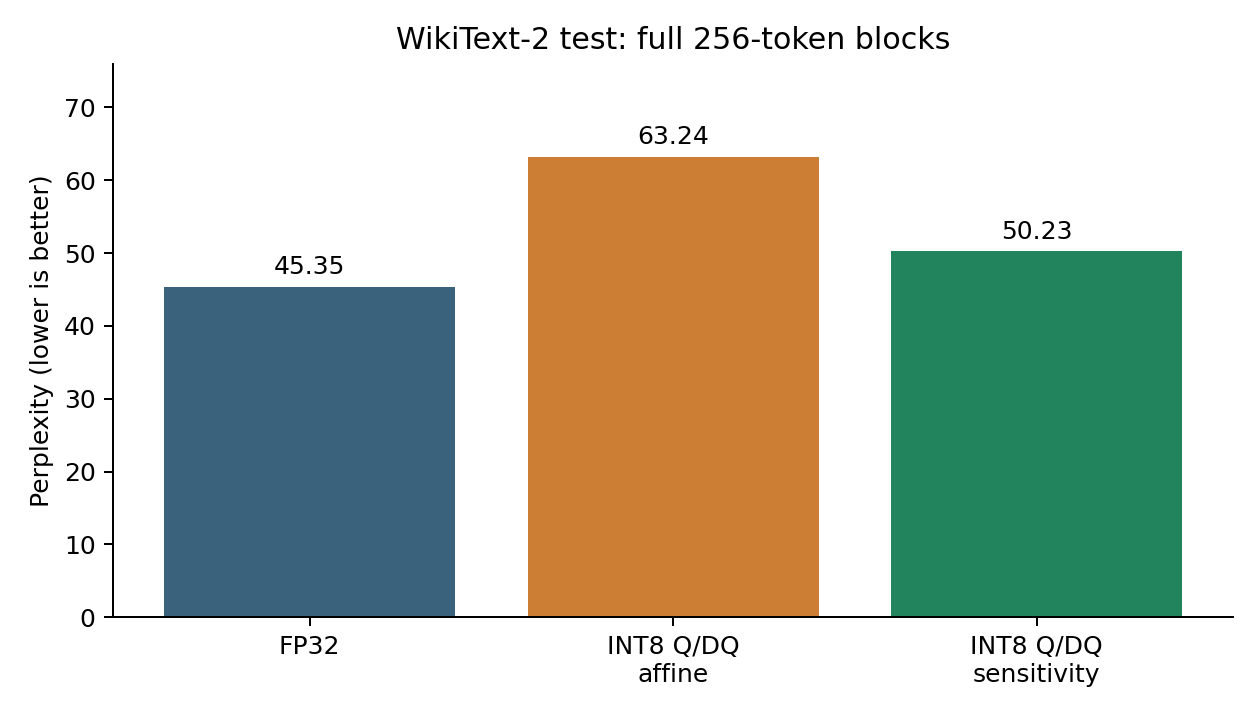

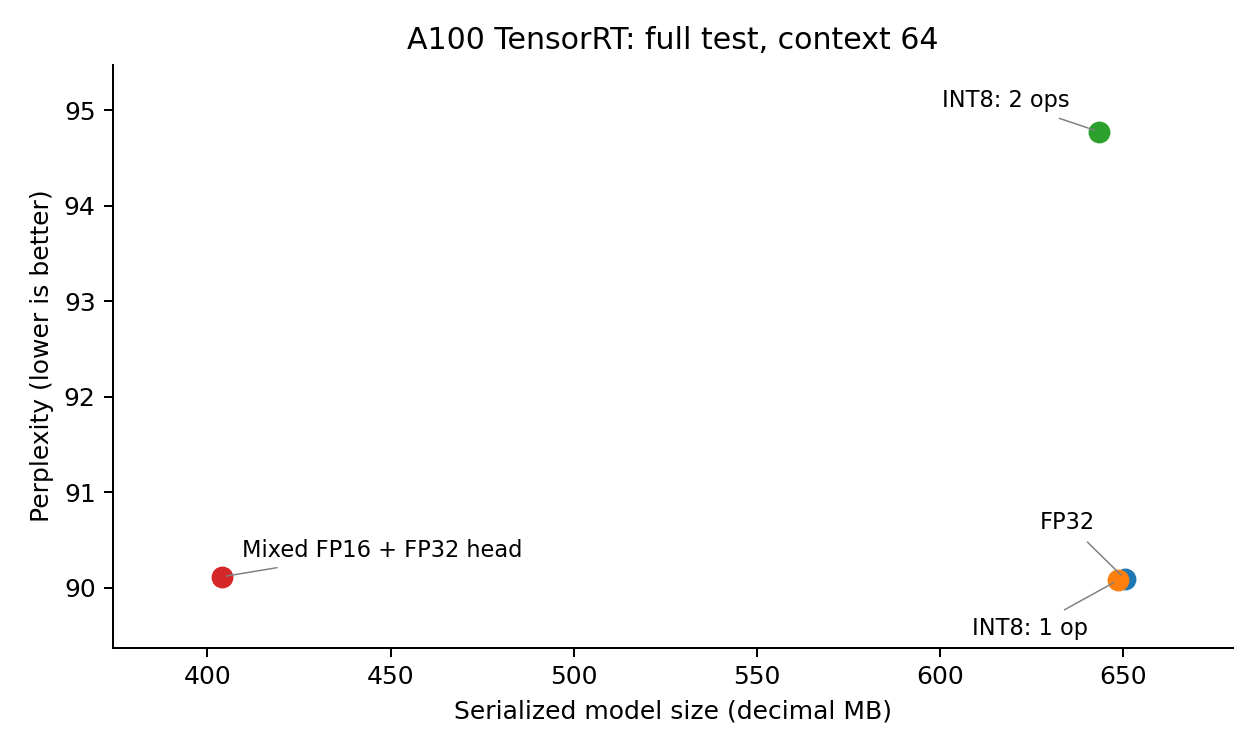

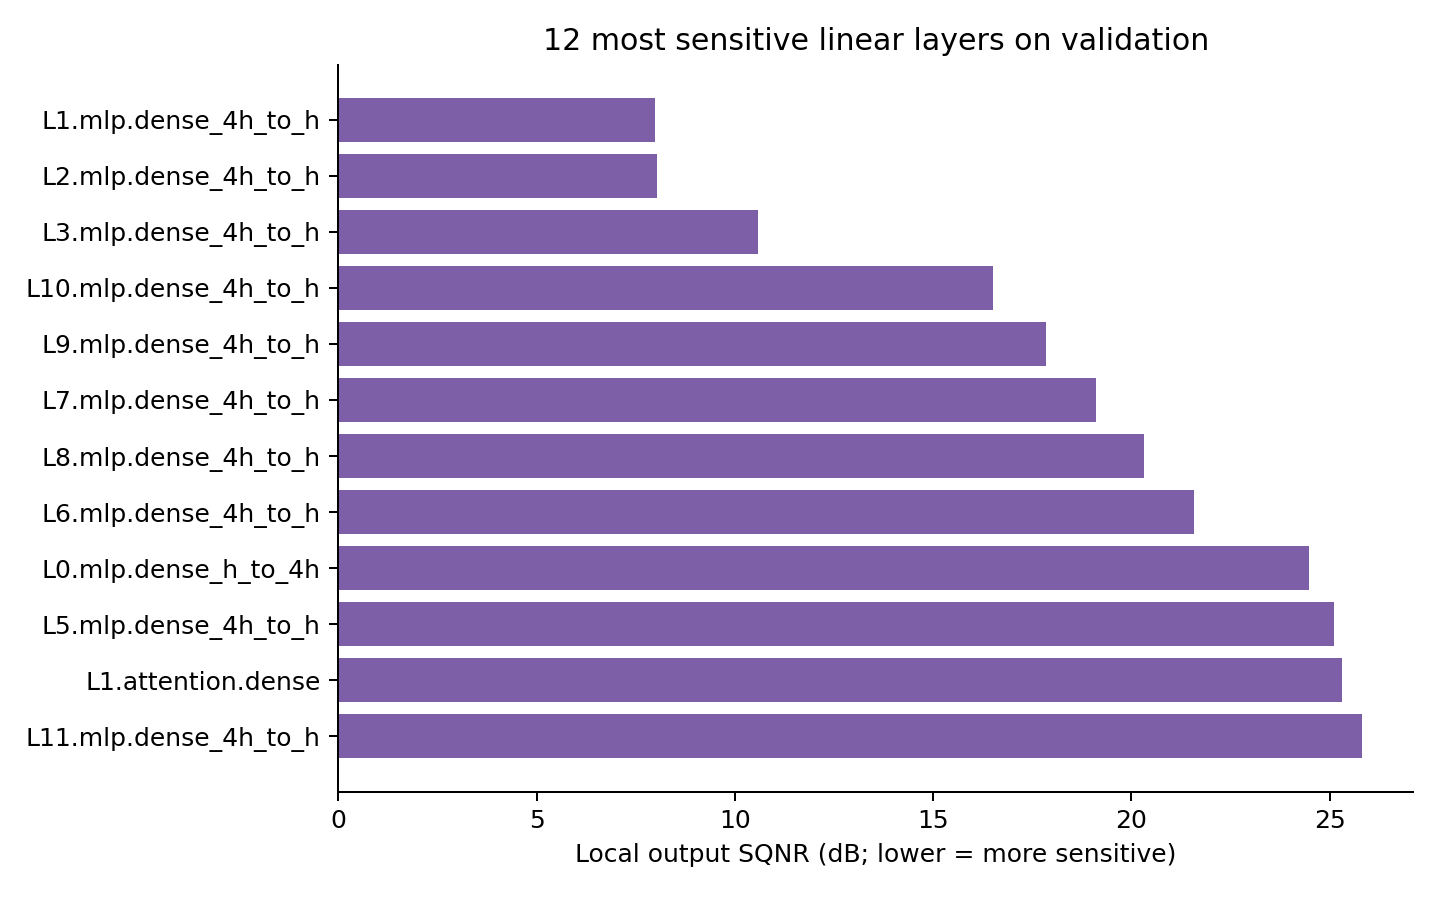



## Дополнительные визуализации

Интервалы ниже получены парным bootstrap по блокам, а не по отдельным токенам. Зависимость соседних блоков может приводить к недооценке неопределённости.

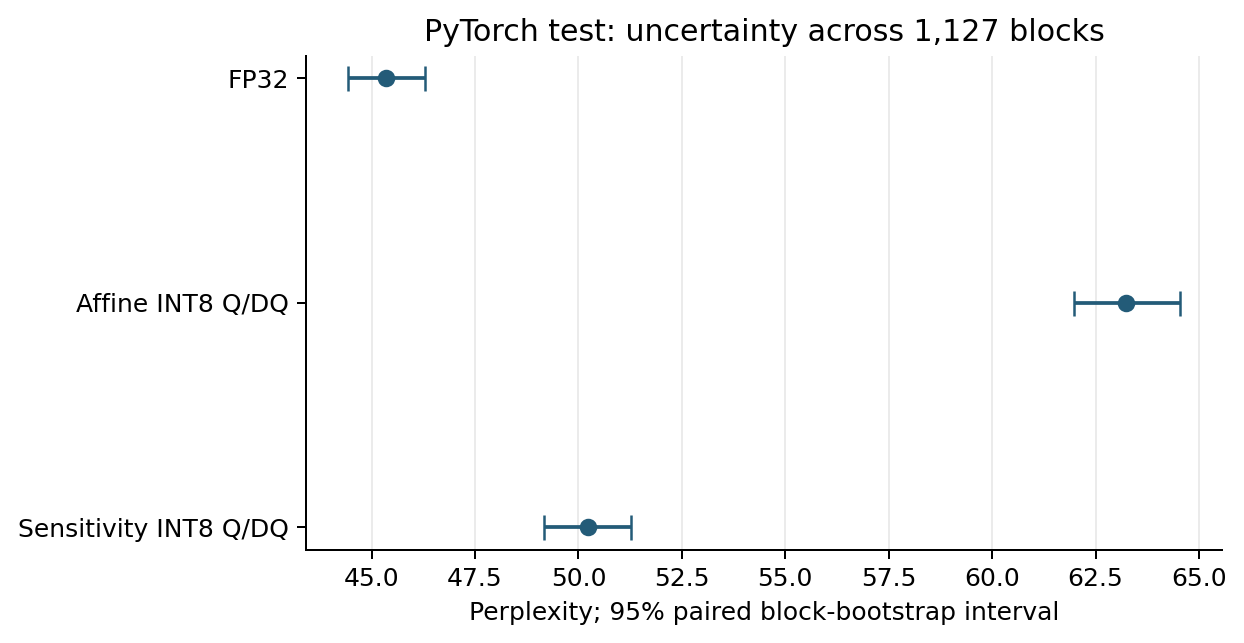

Эти два ряда используют прежние эксперименты с квантованной головой; число калибровочных блоков само по себе не восстанавливает качество.

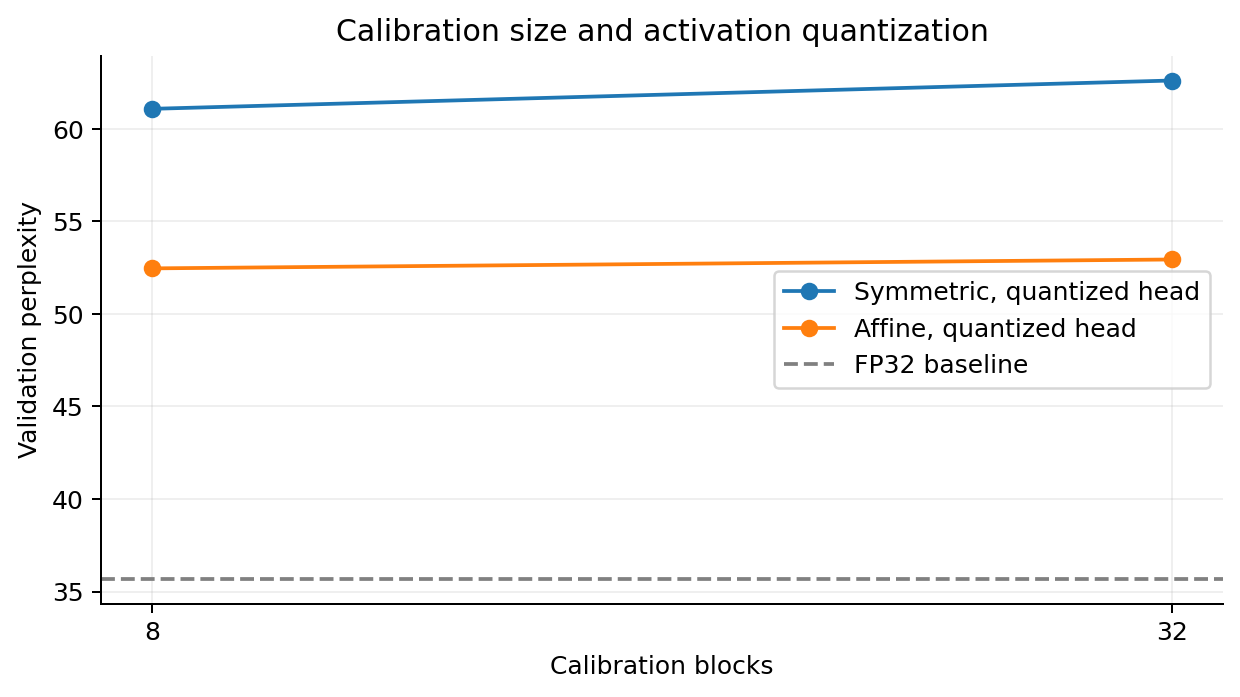

При одинаковом числе исключений выбор по sensitivity заметно лучше случайного контроля. Все четыре варианта на графике используют FP32-голову.

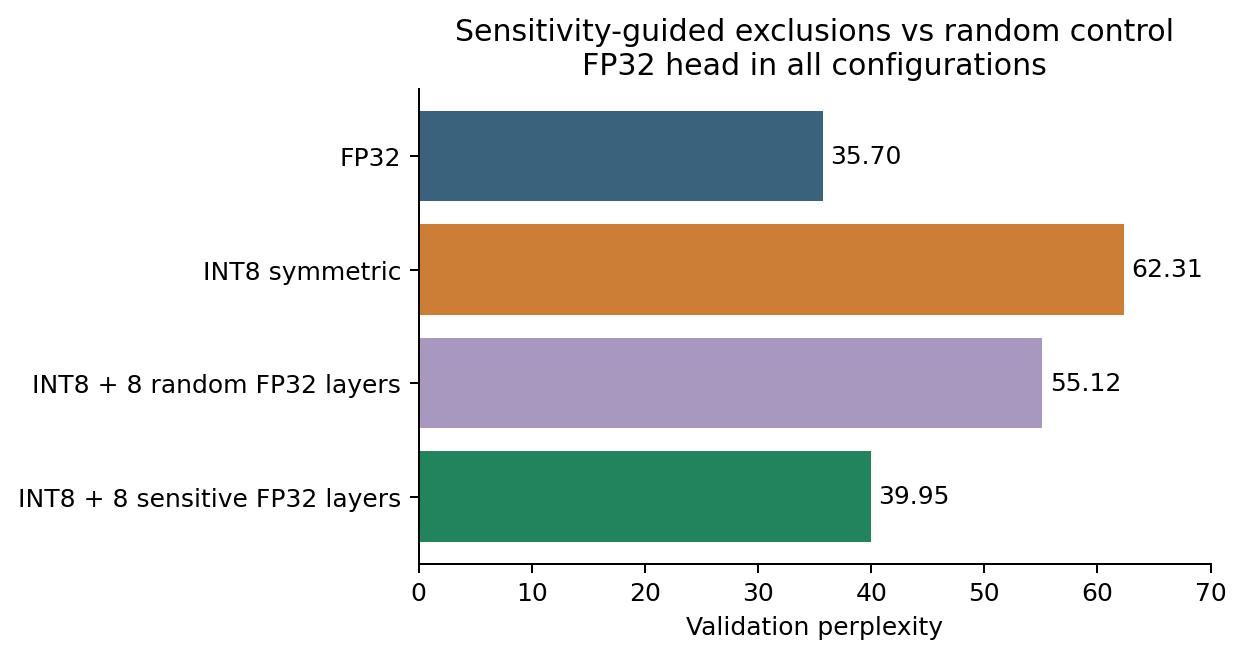

Далее сравниваются гибридные варианты с одинаковой схемой измерений. Задержка включает FP32-голову, память получена выборочным опросом и может не включать краткий пик. PPL измерена на полном test, задержка и память — в отдельных коротких запусках.

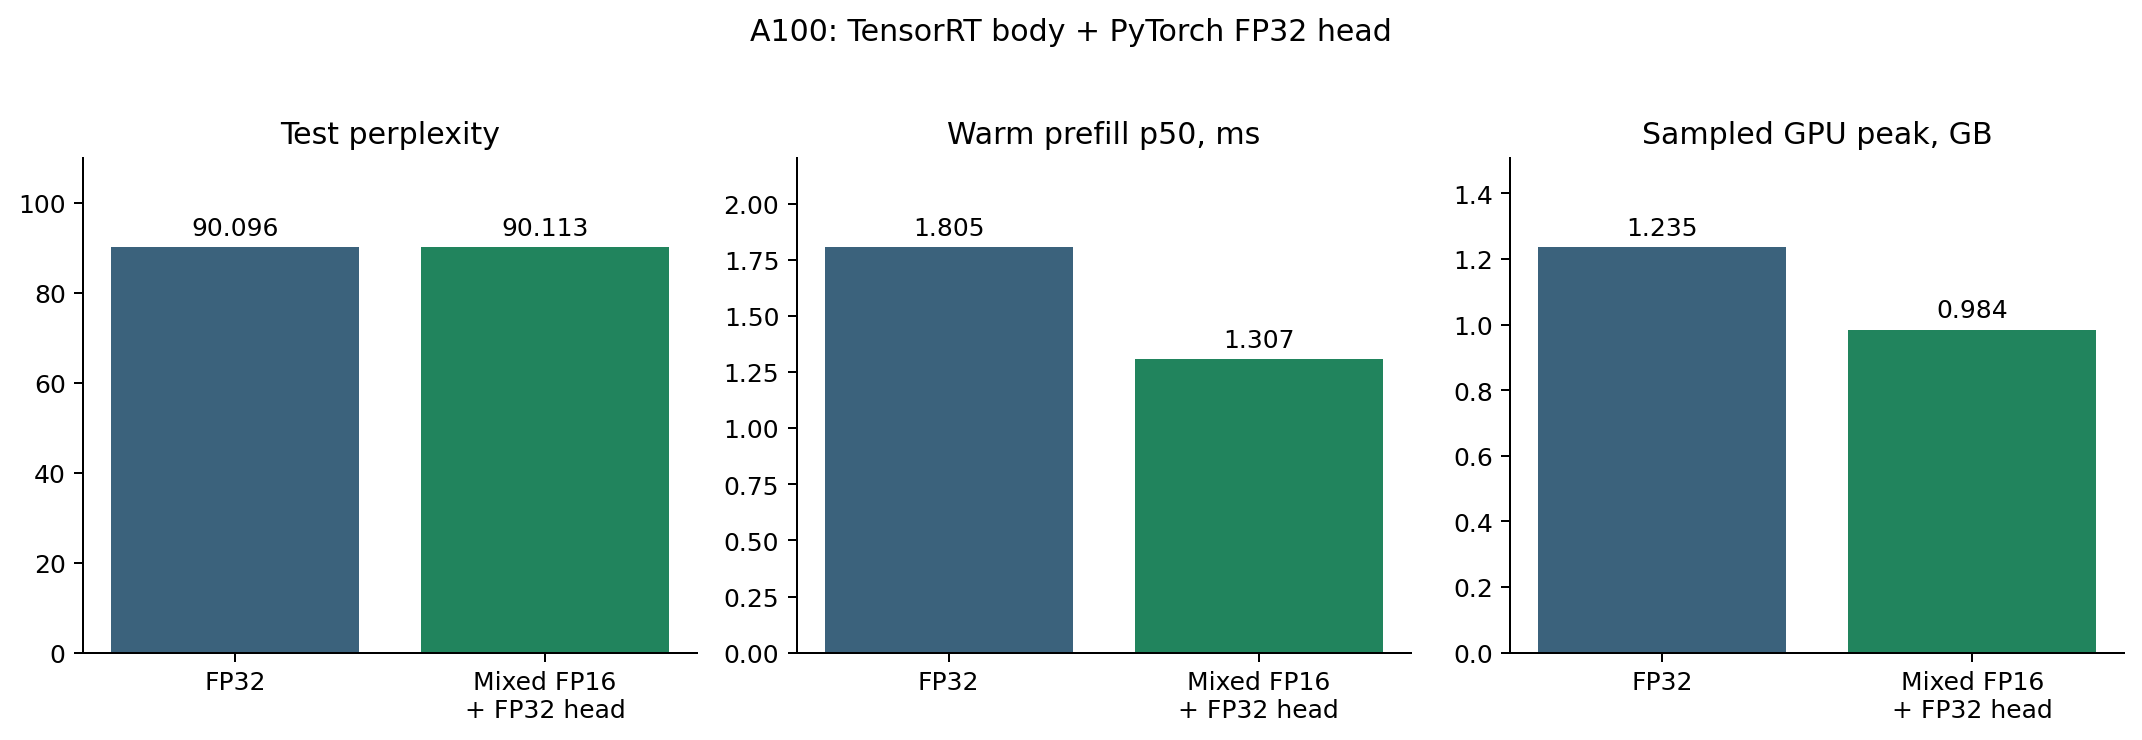

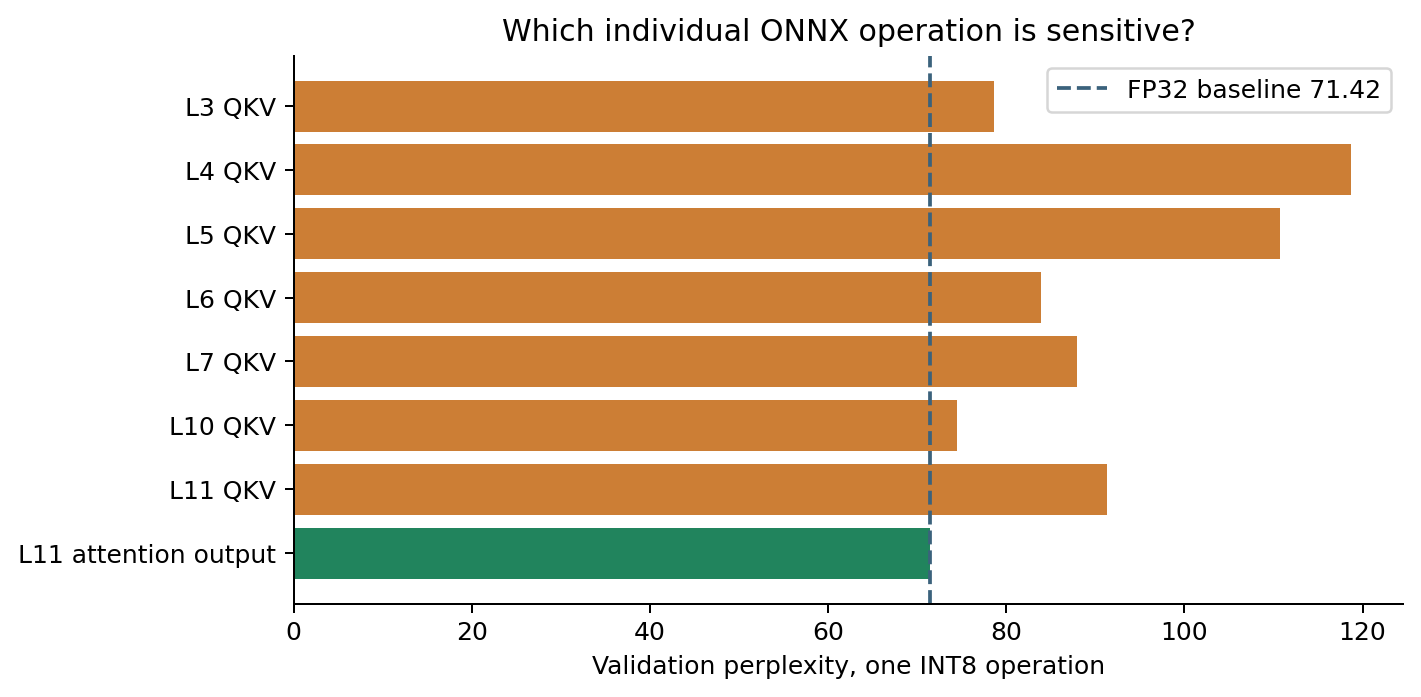

Decode измерен на трёх примерах после прогрева; Q/DQ использует float matmul, поэтому эта диаграмма не характеризует производительность оптимизированного INT8-ядра.

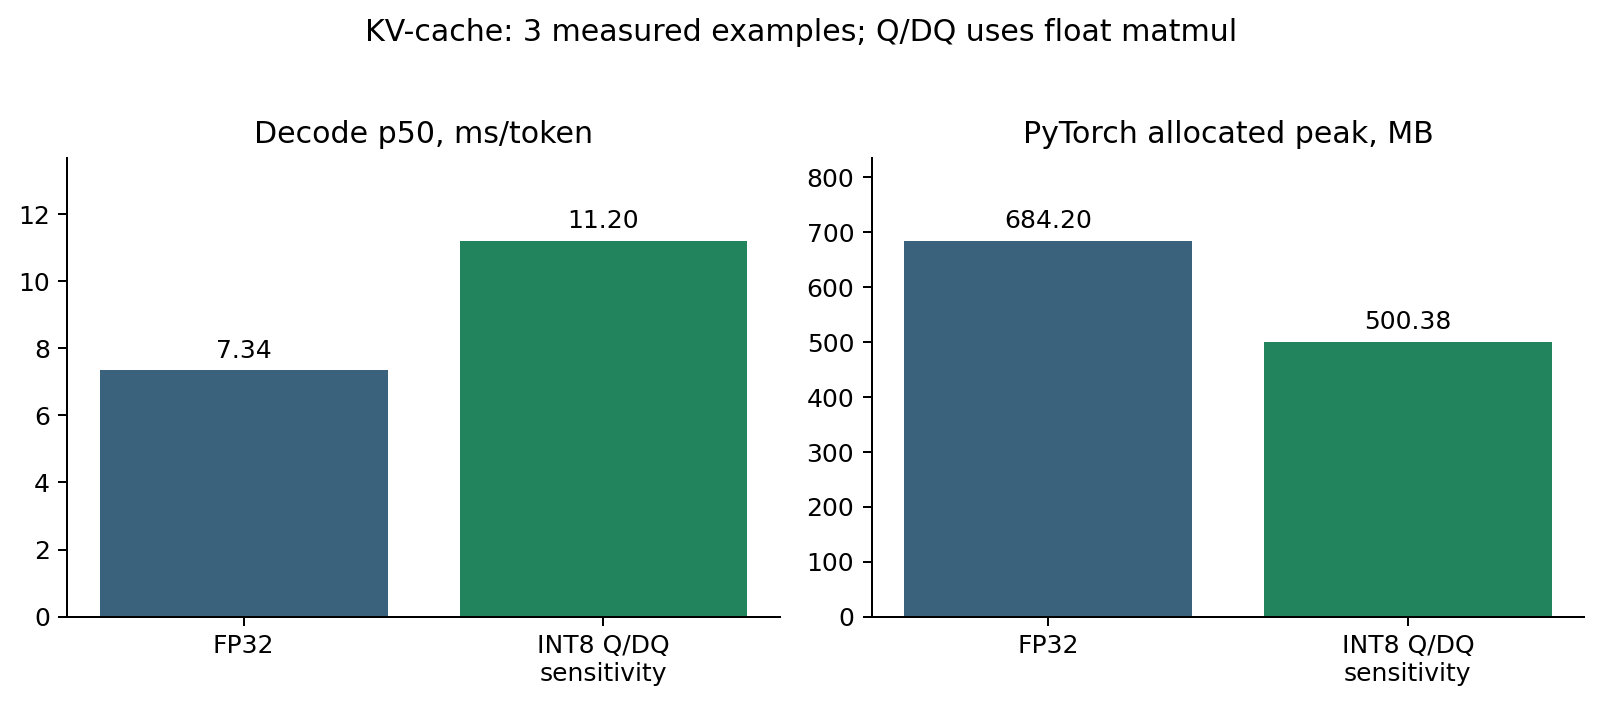



## Ограничения и дальнейшая работа

Полное INT8-квантование графа TensorRT значительно ухудшило качество; сохранение качества достигнуто только при квантовании одной операции, что уменьшило размер всего на 0,27%. Смешанный FP16 TensorRT с отдельной FP32-головой сохранил качество и уменьшил размер, но состоит из двух компонентов. Надёжное ускорение INT8 не доказано: для этого нужны независимые повторные измерения. Пиковая GPU-память получена выборочным опросом и может быть занижена; decode-проверка мала. Bootstrap предполагает взаимозаменяемость блоков. Результаты при контекстах 64 и 256 между собой напрямую не сопоставимы, а возможное пересечение WikiText с предобучением ограничивает обобщение.

Метрики экспериментов доступны в Comet; архив с результатами и журналами сохранён локально у автора. Загрузка последней полной версии архива в Comet ограничена сервисом; ранее загруженный архив и отдельные скалярные метрики доступны в проекте. По просьбе пользователя веса и движки не переносились и удалены с кластера после экспорта результатов.


## Исходный код и запуск
Рядом с ноутбуком находятся упрощённые Python-скрипты для локального запуска. Фактически использованный код экспериментов сохранён в каталоге `pythia_ptq`. Функция ниже не запускает вычисления автоматически; перед запуском установите зависимости.


In [ ]:
# Локальный запуск выбранного скрипта из папки с ноутбуком.
import subprocess, sys
from pathlib import Path
def run_local(script, *args):
    return subprocess.run([sys.executable, str(Path.cwd() / script), *args], check=True)
